# 02 · Analysis: links, gauges and radar in rain and snow

All the sensors of the record on the same days: the links (NYC Mesh), the 1-minute airport gauges (ASOS), the daily
gauges (GHCN) and the radar (MRMS). First three examples, then rain from the links, blackouts and how paths
recover after rain and snow; at the end the ten radar days (5 rain, 5 snow) and the radar along the links.

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve() / "src"))   # the repo's src/
from analysis import v2 as om
DATA = om.setup()                              # D.use('v2'); downloads the record on first run (D.ensure)
meta = om.link_meta()                          # one row per path

## 1. Three examples

For one path per band (the one with the most data that day): the level relative to its median; below, the
precipitation type and amount at the five airport gauges, and the temperature.

**Rain.** The drops follow the rain rate: here up to about 10 dB at 60 GHz, 3 to 4 dB at 24 and 5 GHz.

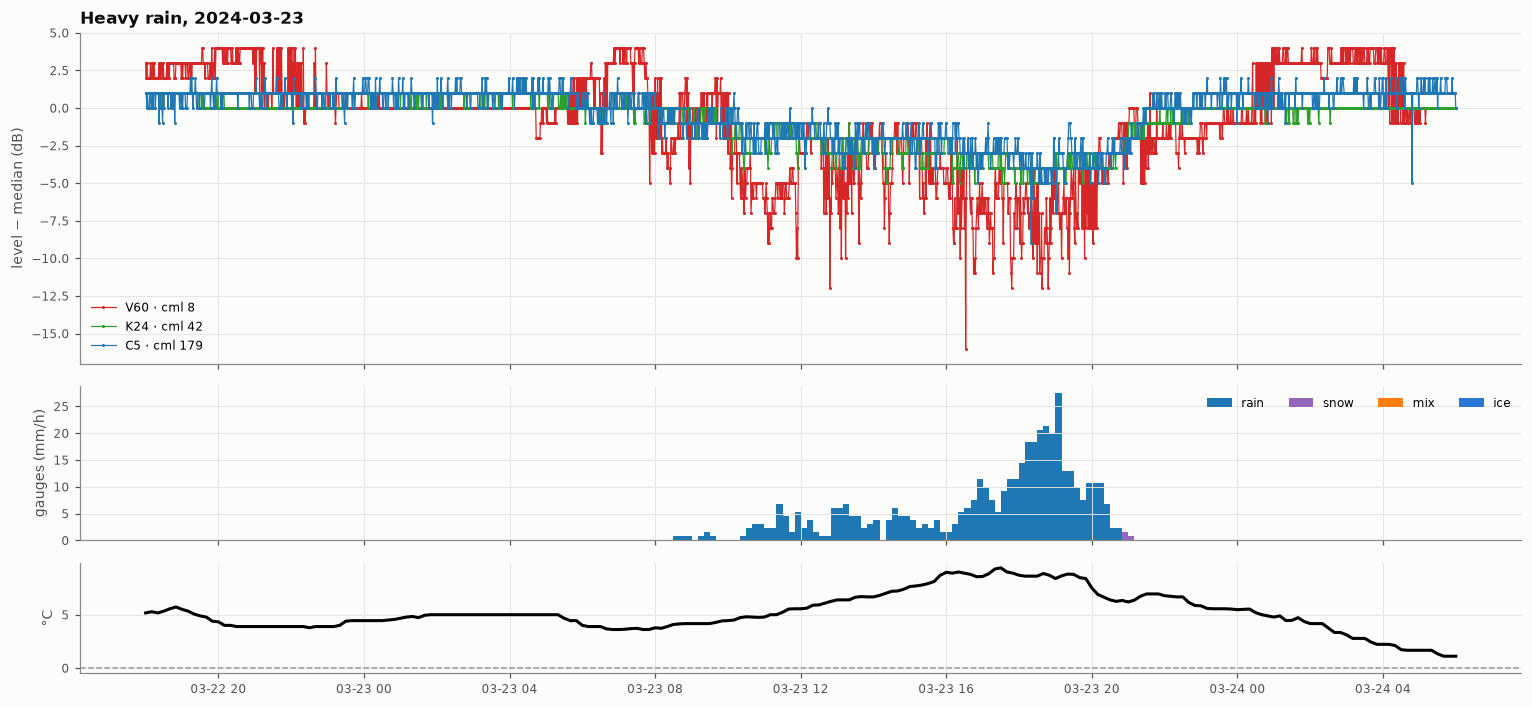

In [2]:
om.plots.show_case("2024-03-23", "Heavy rain, 2024-03-23")

**Dry snow.** Cold, dry snow hardly attenuates (here 1 to 3 dB at most): little liquid water in the path. The
heated gauges report the amount late, as the snow melts.

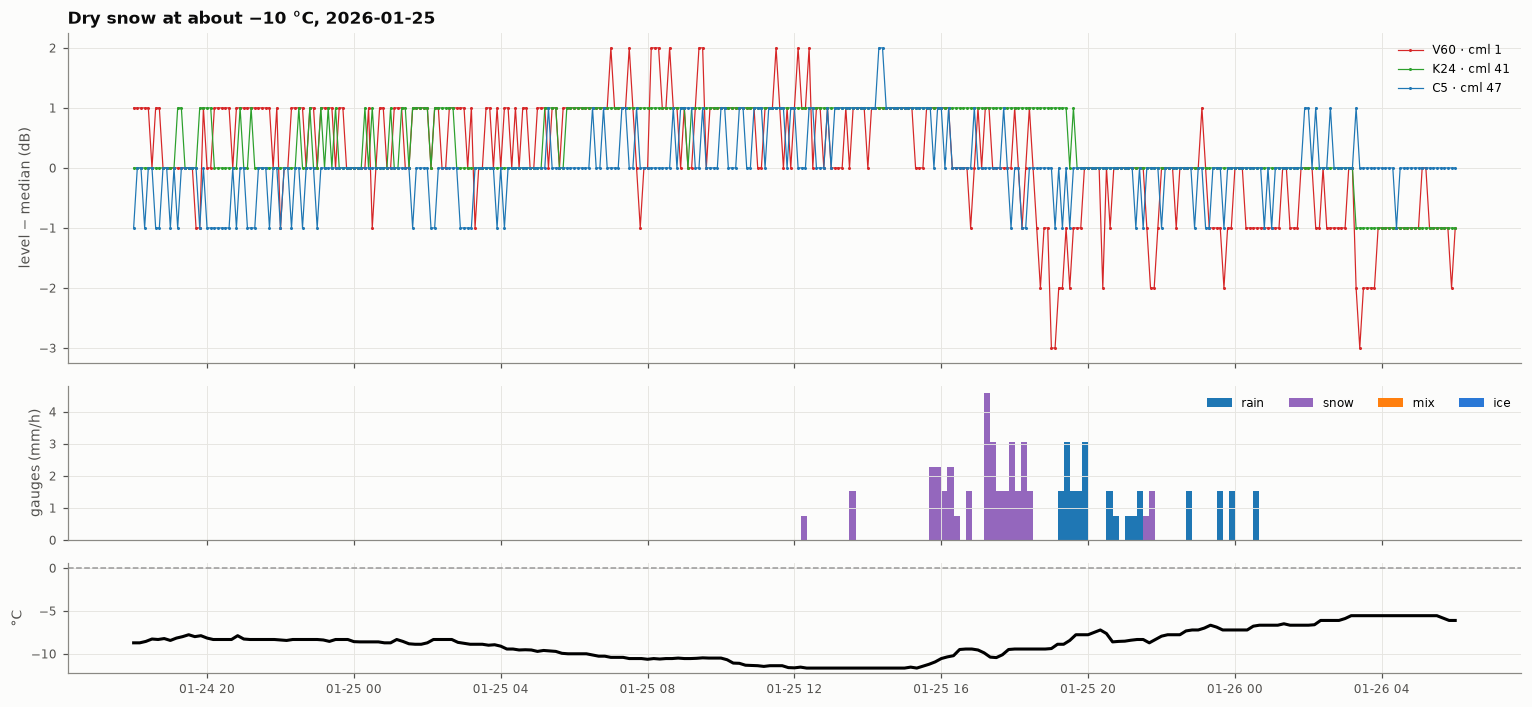

In [3]:
om.plots.show_case("2026-01-25", "Dry snow at about −10 °C, 2026-01-25")

**Wet snow.** Melting snow carries liquid water and wets the antennas: here the 24 GHz path drops about 4 to 5 dB
and the 5 GHz path up to 10 to 15 dB while the gauges see 1 to 3 mm/h; this 60 GHz path moves less.

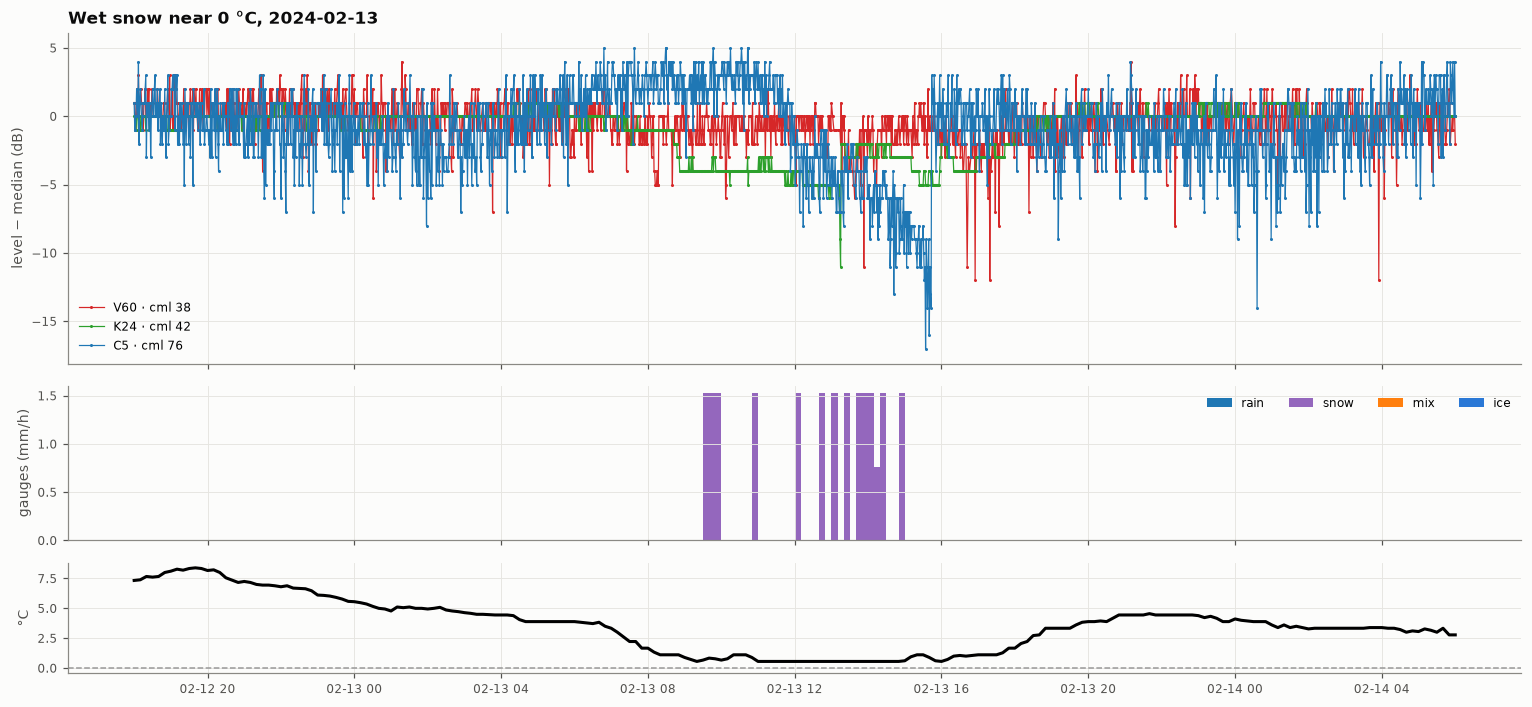

In [4]:
om.plots.show_case("2024-02-13", "Wet snow near 0 °C, 2024-02-13")

Any other day: `om.plots.show_case("2023-12-18")`.

## 2. Rain accumulation: links against radar and gauges

Three rain days with one value per minute. Rain from the links follows the OpenSense processing chain (as in the
pycomlink examples), in plain xarray:

1. **wet / dry**: wet when a gauge records rain within one hour (the gauge network as reference);
2. **baseline**: the median level of the dry minutes over the past 6 hours, held through the wet spells;
3. **attenuation** `A = baseline − level` (no wet-antenna correction, so wet antennas add to the estimate);
4. **rain rate** from the ITU-R P.838-3 power law `A = a R^b L` (`analysis.itu_rainrate.rain_rate`).

Only 60 GHz paths of at least 800 m with 90 % of the day's minutes and at most 1.5 dB of noise when dry are used:
at 5 GHz one dB is already about 100 mm/h, so the stored whole-dB levels give no usable rain there. The radar is the
MRMS hourly rain averaged along the same paths (`poligrain.spatial.GridAtLines`); the metrics come from
`poligrain.validation`. Set `PICK` to a list of `cml_id` to choose the paths yourself; `om.analysis.link_rain(day, cml_ids)` gives the minute series of any path.

In [5]:
EVENTS = ["2023-11-22", "2023-12-18", "2024-03-23"]   # rain days with one value per minute
PICK = None                                            # or a list of cml_id, e.g. ["6", "17", "21"]
table, acc = om.analysis.rain_accumulation(EVENTS, pick=PICK)
table

,2023-11-22,2023-12-18,2024-03-23
paths,"10, 16, 17, 19, 21, 38","6, 10, 16, 17, 19, 21, 38","6, 9, 10, 17, 19, 21, 30, 38"
"links, median (mm)",51.3,83.6,67.1
radar along the paths (mm),42.8,66.8,74.2
"ASOS, median (mm)",50.5,69.3,85.9
"GHCN, median (mm)",28.0,45.7,84.3


The accumulation over each UTC day: every picked path (thin), their median (bold), the radar along the same
paths, the gauges and the GHCN day total.

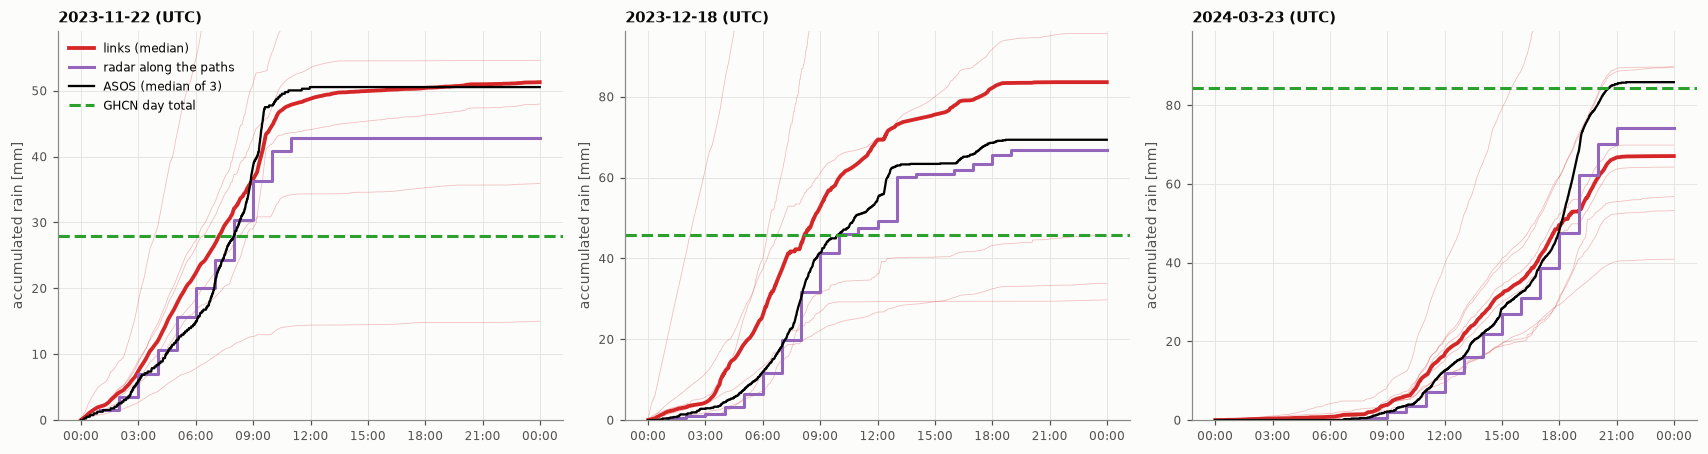

In [6]:
om.plots.accumulation(acc)

## 3. Blackouts: links that drop out in rain

When rain attenuates a path below what its receiver can hear, the network stores no value: the path goes dark.
Below, the share of minutes without a value (`sublink_1` of the paths alive that day) in dry minutes, light rain and
heavy rain at the gauges; then three examples.

In [7]:
om.analysis.outages(EVENTS)

paths   dry light (< 10 mm/h) heavy (≥ 10 mm/h)  heavy-rain minutes
day        band                                                                     
2023-11-22 V60       8  2.2%              2.2%             10.8%                 245
           K24       2  0.1%              0.0%              0.0%                 245
           C5      300  3.6%              4.0%              4.8%                 245
2023-12-18 V60       8  2.5%              3.7%             14.3%                 254
           K24       2  0.1%              0.5%              1.8%                 254
           C5      298  4.0%              4.7%             10.4%                 254
2024-03-23 V60      12  1.4%              2.0%              5.5%                 560
           K24       2  0.4%              1.0%              0.7%                 560
           C5      323  3.7%              3.7%              6.1%                 560

Three paths that go dark in heavy rain: a steady level before, a fall of 10 to 15 dB as the rain arrives,
no value while the rain is heaviest, and the same level again afterwards. The gauge is several km away, so its rain
is not exactly the rain on the path. Path 39 is dual-frequency: its 5 GHz sublinks keep working while the 60 GHz
ones are dark. `om.plots.blackouts([(cml_id, start, end), ...])` shows any other path.

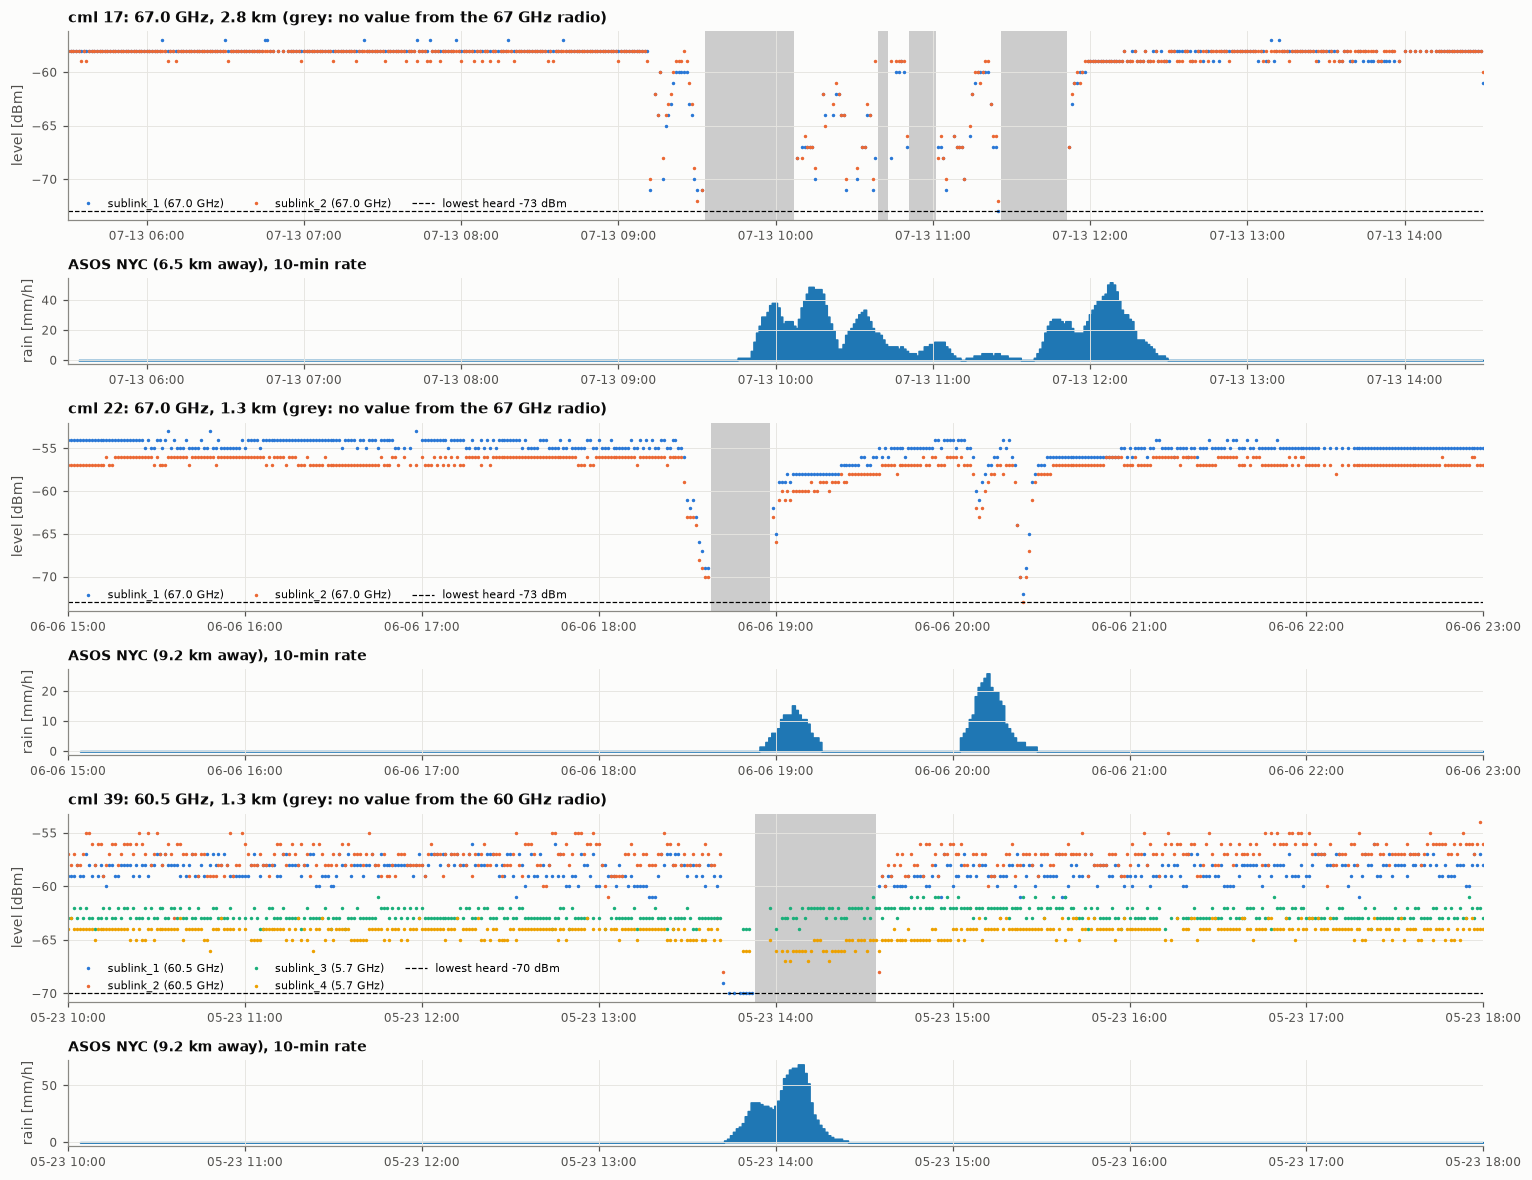

In [8]:
om.plots.blackouts()

## 4. After the rain or snow: how fast a path recovers

Water, wet snow and ice on an antenna or its radome attenuate a link too, not only the precipitation along the path.
Six examples, each from 24 h before the end of the event to 48 h after it (shaded: the event; dashed: the dry level
of the 24 h before it). Without precipitation a 60 GHz level holds within about 1 dB. After rain the level is back
almost at once. After wet snow it takes a few hours; after cold snow a path can stay several dB down for a day or
more, while snow or ice stays on the antenna. These effects are studied over all the events of the record in
Jacoby et al. (ACM SenSys 2027). `om.plots.antenna_examples([(title, cml_id, sublink, start, end), ...])` shows any
other path and event.

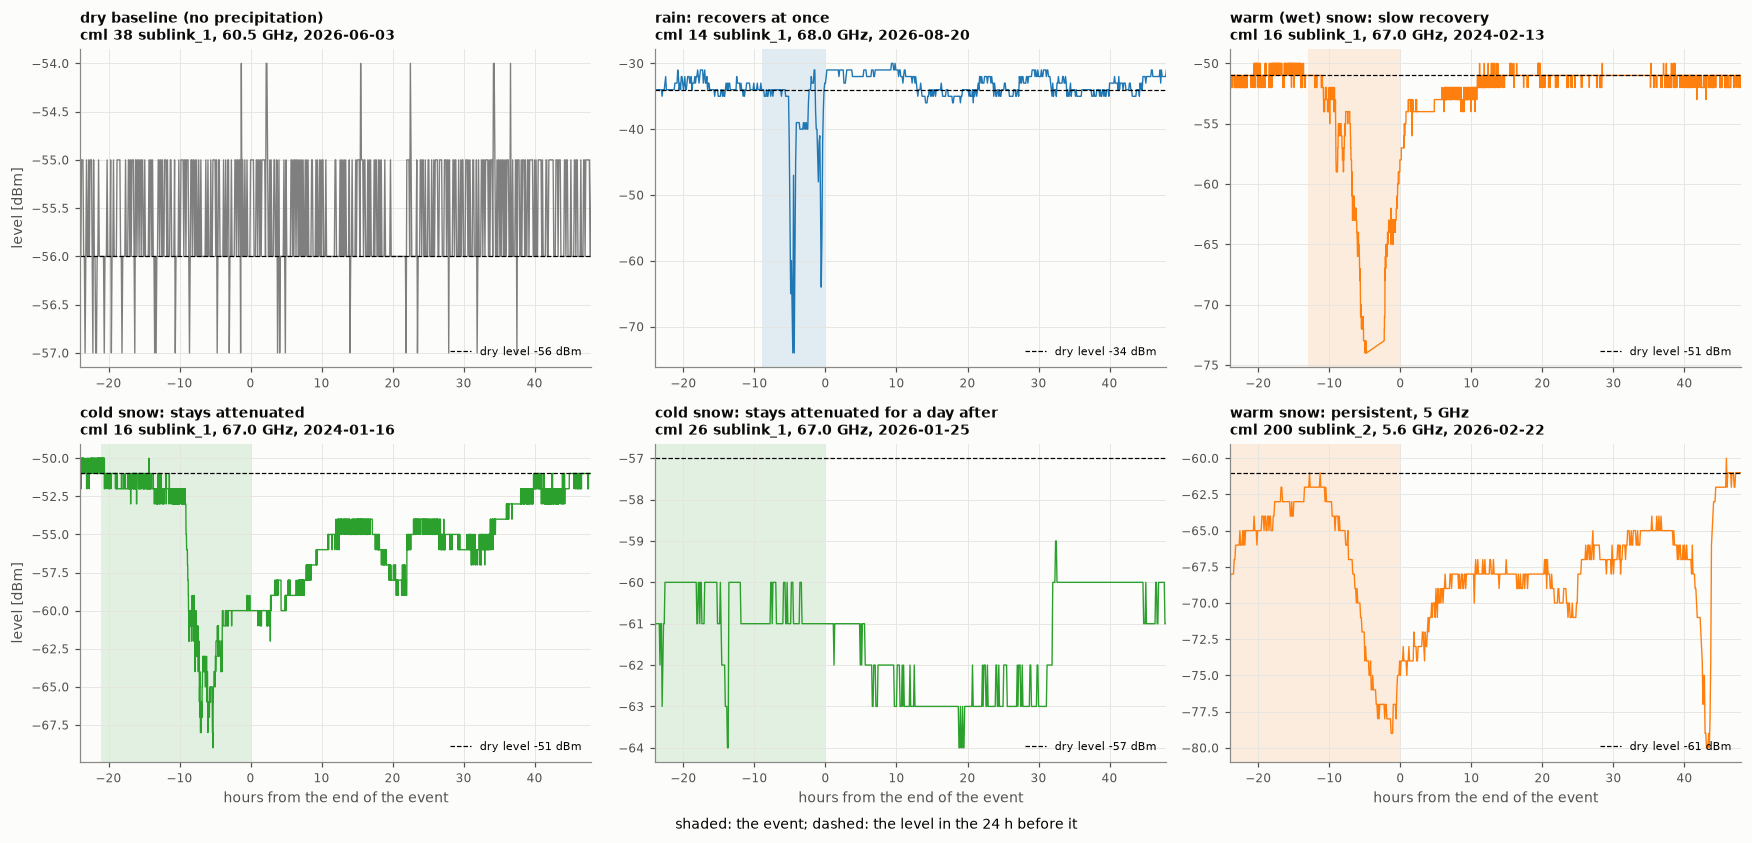

In [9]:
om.plots.antenna_examples()

**The dry baseline.** Attenuation is the drop below the level the path would have without precipitation,
A = baseline − level. Two simple baselines on the 2026-08-20 rain (path 14, 68 GHz): a constant, the median of
the 24 h before the event (red), and a rolling median over 24 h (green; `om.analysis.attenuation`). During the
rain both give the same A, up to 40 dB. After it this path settles about 2 dB higher than before, so the constant
baseline turns slightly negative while the rolling median follows; over a long event a rolling median sinks
towards the attenuated level instead. A retrieval also needs a wet/dry classification and a wet-antenna term.
`om.plots.baseline_methods(cml_id, sublink, start, end, event=(start, end))` for any other path and event.

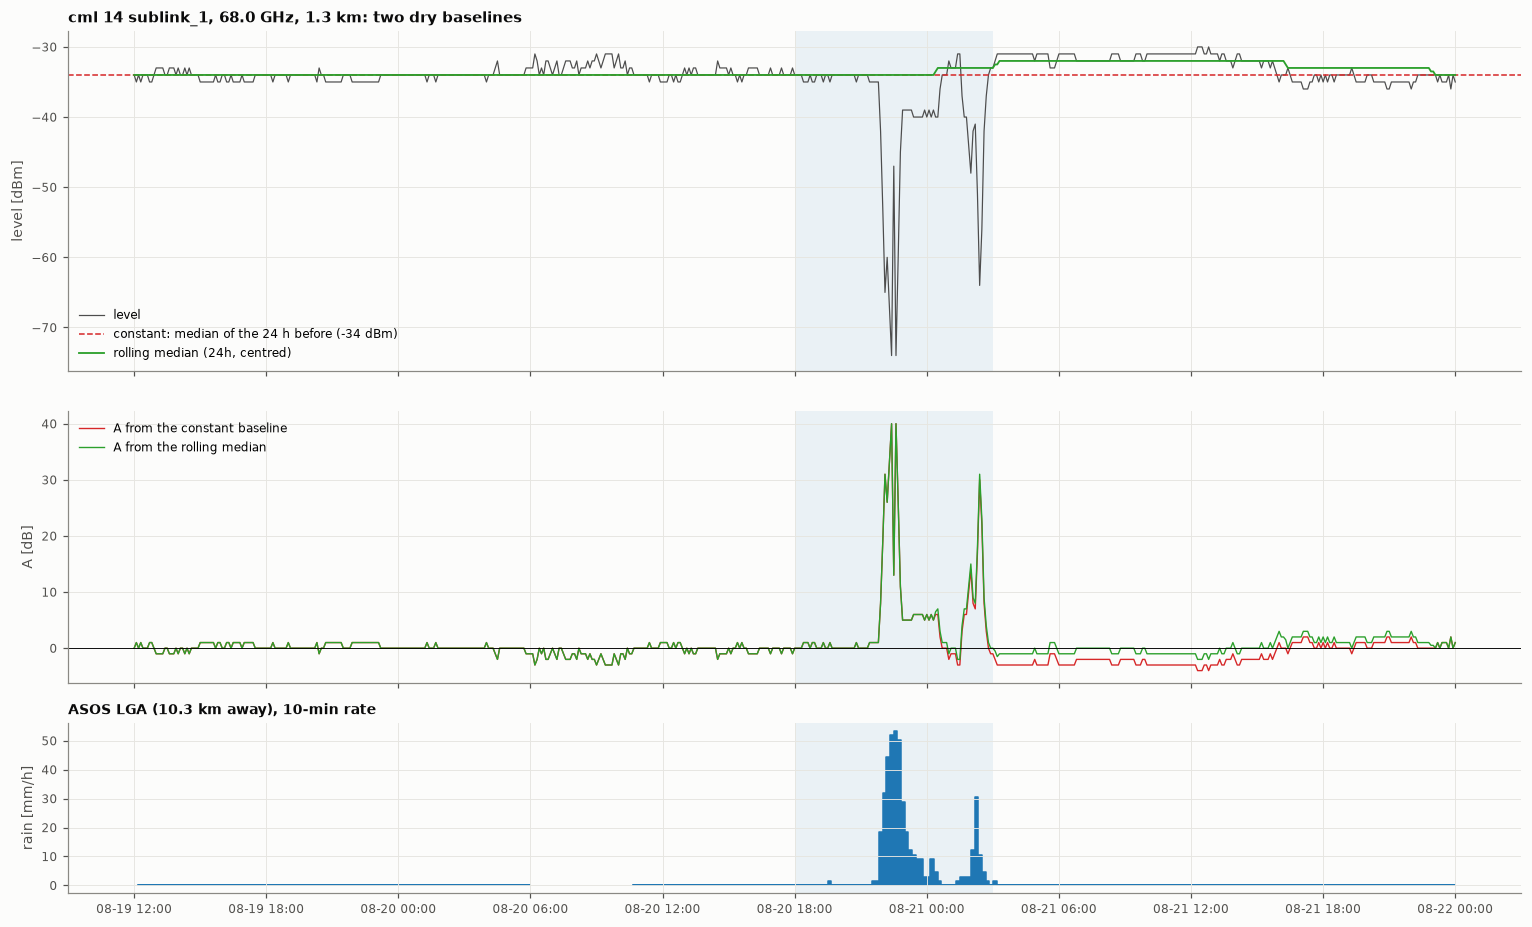

In [10]:
om.plots.baseline_methods()

## 5. The ten radar days

NOAA MRMS over New York City on five rain and five snow days, with the ASOS median and the radar mean and maximum.

In [11]:
ev = om.radar_events()
ev[["kind", "day", "asos_median_mm", "radar_mean_mm", "radar_max_mm", "rain_share", "snow_share"]]

,kind,day,asos_median_mm,radar_mean_mm,radar_max_mm,rain_share,snow_share
0,rain,2023-11-22,39.12,38.3,55.3,0.933,0.005
1,rain,2023-12-18,69.34,66.4,96.7,0.918,0.027
2,rain,2024-03-10,36.07,34.3,48.8,0.871,0.007
3,rain,2024-03-23,85.85,72.0,96.6,0.931,0.028
4,rain,2025-10-30,45.97,49.5,76.9,0.857,0.037
5,snow,2024-02-13,16.51,17.3,29.7,0.141,0.805
6,snow,2025-12-14,13.21,13.8,20.9,0.032,0.931
7,snow,2025-12-27,8.76,9.4,16.0,0.030,0.960
8,snow,2026-01-25,20.96,30.2,42.4,0.263,0.734
9,snow,2026-02-23,9.40,43.2,53.6,0.012,0.949


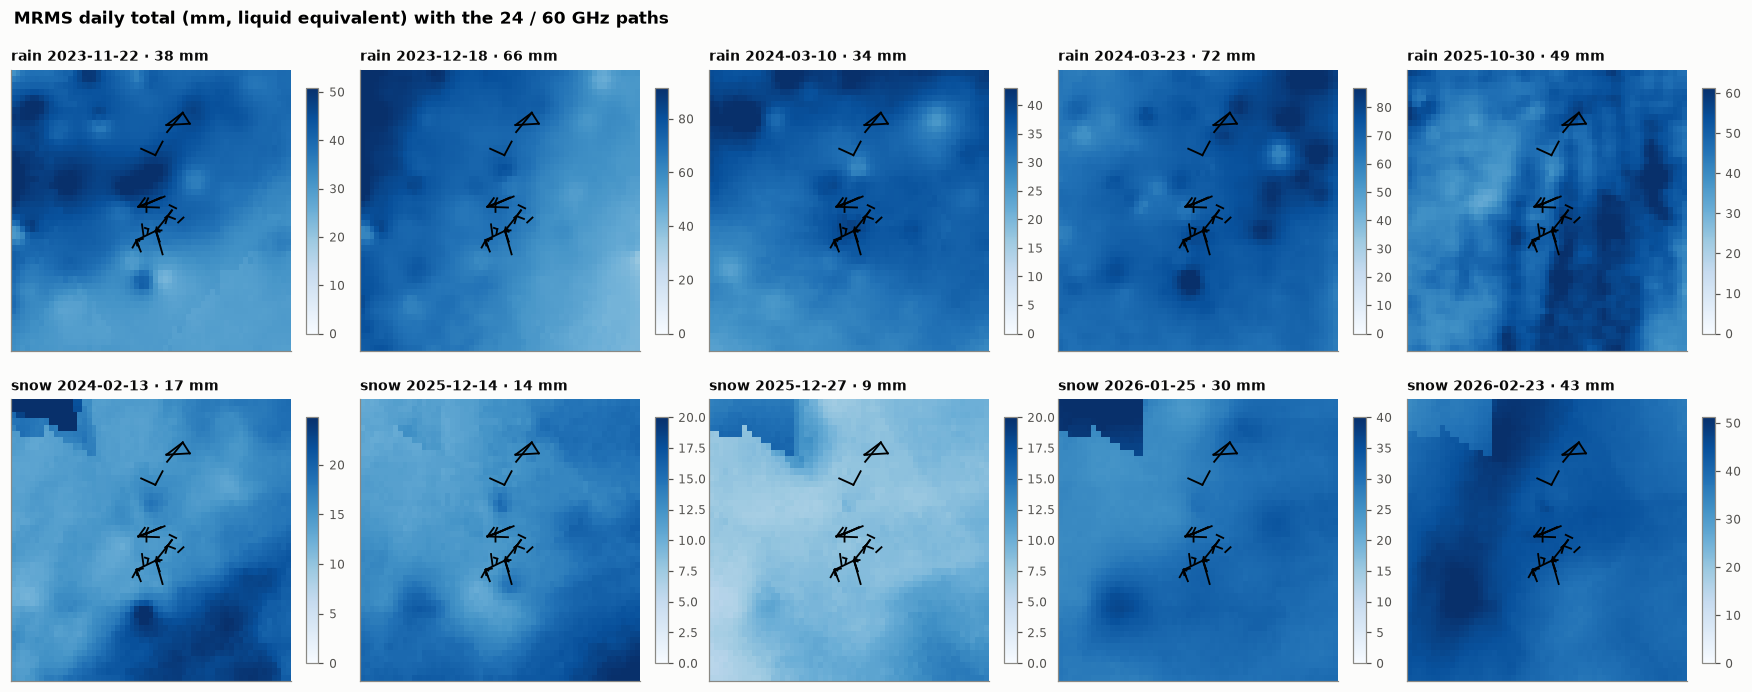

In [12]:
om.plots.radar_maps(meta)

**The daily gauges (GHCN) on the same days.** Each station's day is its own observing window (e.g. 07:00 to
07:00 local for CoCoRaHS); shown is the window that covers most of the UTC day. Snowfall is the depth of new snow,
not its water.

In [13]:
g = pd.read_csv(DATA / "data" / "weather" / "ghcn" / "ghcn_daily.csv", parse_dates=["day_start_utc", "day_end_utc"])
rows = []
for e in ev.itertuples():
    d = e.day
    q = g[(g.day_end_utc > d) & (g.day_start_utc < d + pd.Timedelta("1D"))].copy()
    q["overlap"] = q.day_end_utc.clip(upper=d + pd.Timedelta("1D")) - q.day_start_utc.clip(lower=d)
    q = q.sort_values("overlap").groupby("ghcn_id").tail(1)
    rows.append(dict(kind=e.kind, day=d.date(), stations=len(q), precipitation_mm=q.precipitation_mm.median(),
                     snowfall_mm=q.snowfall_mm.median(), asos_median_mm=e.asos_median_mm, radar_mean_mm=e.radar_mean_mm))
pd.DataFrame(rows).round(1)

,kind,day,stations,precipitation_mm,snowfall_mm,asos_median_mm,radar_mean_mm
0,rain,2023-11-22,6,28.0,0.0,39.1,38.3
1,rain,2023-12-18,6,45.7,0.0,69.3,66.4
2,rain,2024-03-10,6,0.8,0.0,36.1,34.3
3,rain,2024-03-23,7,84.3,0.0,85.8,72.0
4,rain,2025-10-30,7,52.2,0.0,46.0,49.5
5,snow,2024-02-13,7,16.3,84.0,16.5,17.3
6,snow,2025-12-14,6,12.8,70.0,13.2,13.8
7,snow,2025-12-27,7,4.1,51.0,8.8,9.4
8,snow,2026-01-25,7,37.6,282.0,21.0,30.2
9,snow,2026-02-23,7,28.0,277.0,9.4,43.2


## 6. Radar along the links

The wettest rain day: the radar field, and every path coloured by the radar rain along it.

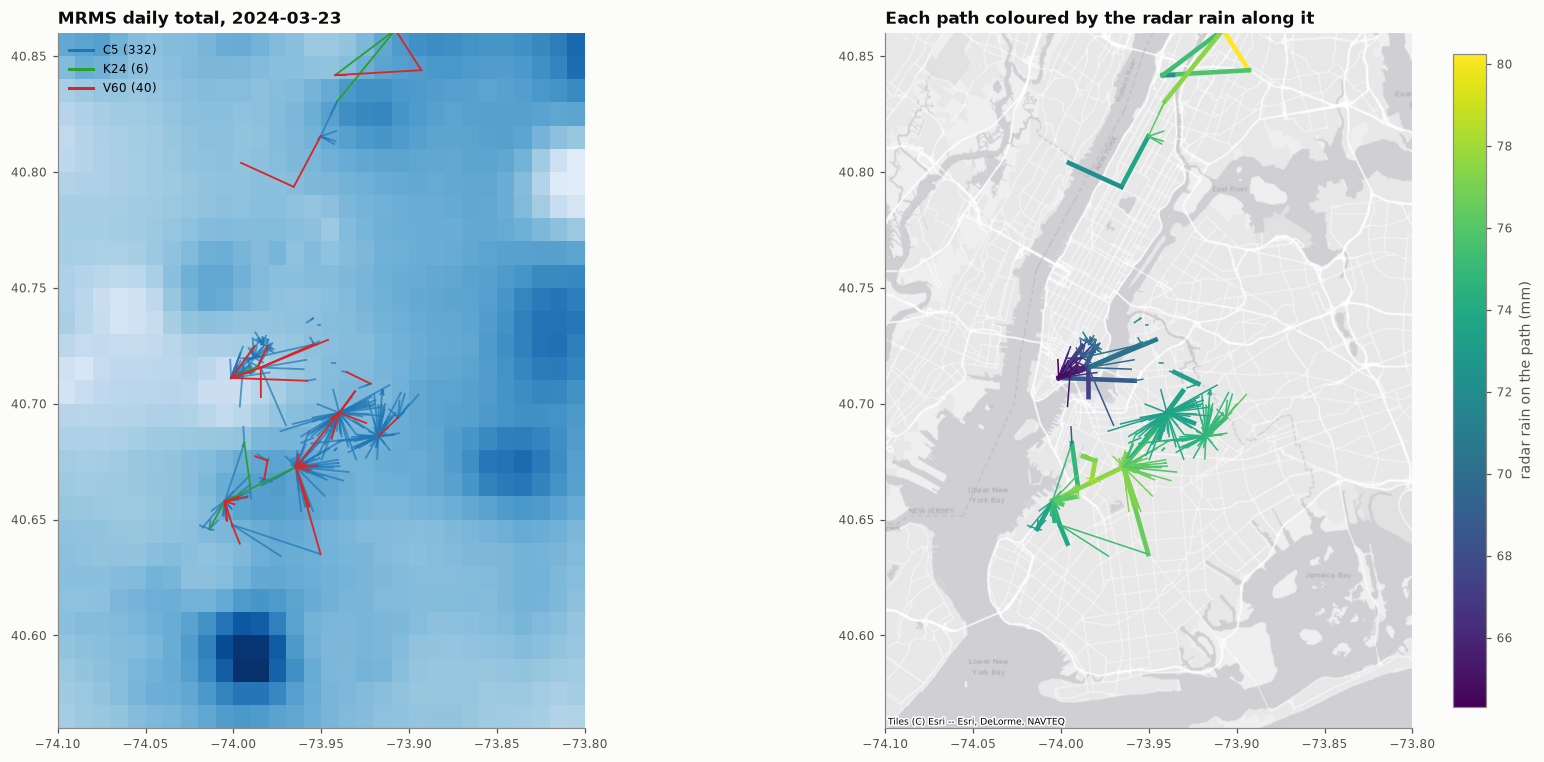

In [14]:
om.plots.radar_along_links(meta)

## 7. Use the radar and the links yourself

Three short cells in plain xarray, without the helper functions. **From signal to rain** on one 60 GHz path: the dry
level is the median of the day before, the attenuation is `A = dry level − level` (negative values set to 0), and
the ITU-R P.838 power law turns `A` into a rain rate (`analysis.itu_rainrate.rain_rate`, from the path's length,
frequency and polarization). No wet/dry classification and no wet-antenna correction: a first look only.

In [15]:
from analysis.itu_rainrate import rain_rate
DAY, CML, SUB = "2024-03-23", "17", "sublink_1"
links = xr.open_dataset(DATA / "data" / "links" / "openmesh_links.nc")
x = links.sel(cml_id=CML, sublink_id=SUB)
level = x.rsl.sel(time=slice("2024-03-22", f"{DAY} 23:59")).to_series()     # one value per minute in 2024
dry = level["2024-03-22"].median()                                         # the dry day before
A = (dry - level[DAY]).clip(lower=0)                                       # attenuation, dB
R = pd.Series(rain_rate(A.values, float(x.length), float(x.frequency), str(x.polarization.values)), index=A.index)
print(f"cml {CML}: {float(x.frequency) / 1000:.1f} GHz, {float(x.length):.0f} m; dry level {dry:.0f} dBm; "
      f"max A {A.max():.0f} dB, max R {R.max():.0f} mm/h")

cml 17: 67.0 GHz, 2790 m; dry level -54 dBm; max A 23 dB, max R 19 mm/h


**The radar along the same path**: the MRMS hourly rain at 20 points from one end of the path to the other
(the nearest grid cell of each), averaged, next to the link's rain and the nearest gauge, hour by hour. All three are
labelled by the end of the hour.

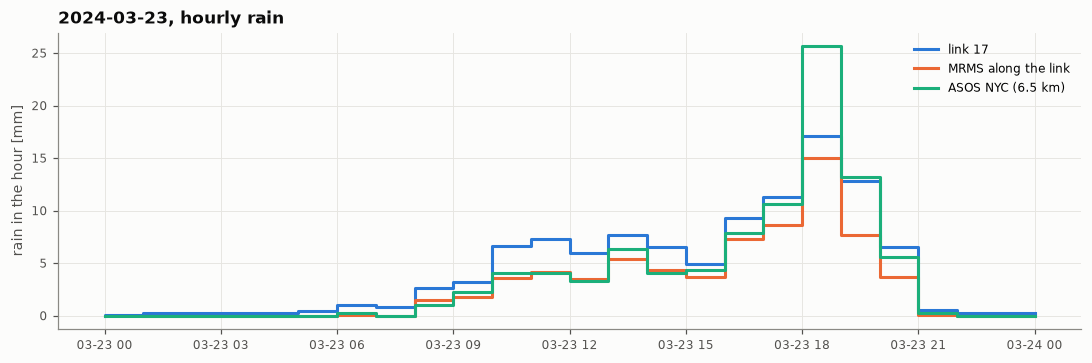

day totals: link 106 mm, radar 70 mm, gauge 93 mm


In [16]:
radar = xr.open_dataset(DATA / "data" / "weather" / "radar" / f"openmesh_radar_rain_{DAY}.nc")
lat = xr.DataArray(np.linspace(float(x.site_0_lat), float(x.site_1_lat), 20), dims="p")
lon = xr.DataArray(np.linspace(float(x.site_0_lon), float(x.site_1_lon), 20), dims="p")
radar_1h = radar.rainfall_amount_1h.sel(lat=lat, lon=lon, method="nearest").mean("p").to_series()
link_1h = R.resample("1h", closed="right", label="right").mean()          # mean mm/h over the hour = mm
asos = xr.open_dataset(DATA / "data" / "weather" / "asos" / "openmesh_asos.nc")
near = om.analysis.nearest(om.asos_stations(), float(x.site_0_lat + x.site_1_lat) / 2, float(x.site_0_lon + x.site_1_lon) / 2)
g = asos.rainfall_amount.where(asos.rainfall_flag == 0).sel(id=near.index[0], time=slice(DAY, f"{DAY} 23:59"))
gauge_1h = g.to_series().resample("1h", closed="right", label="right").sum(min_count=30)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.step(link_1h.index, link_1h.values, where="pre", label=f"link {CML}")
ax.step(radar_1h.index, radar_1h.values, where="pre", label="MRMS along the link")
ax.step(gauge_1h.index, gauge_1h.values, where="pre", label=f"ASOS {near.index[0]} ({near.distance_m.iloc[0] / 1000:.1f} km)")
ax.set_ylabel("rain in the hour [mm]"); ax.set_title(f"{DAY}, hourly rain", loc="left"); ax.legend(); plt.show()
print(f"day totals: link {link_1h.sum():.0f} mm, radar {radar_1h.sum():.0f} mm, gauge {gauge_1h.sum():.0f} mm")

**Precipitation type**: KOKX `hydrometeor_class` is the type aloft (about 1 to 2 km above the city), MRMS
`precip_flag` the type at the ground; both are codes (see the variables' attributes and the record's README.md). On 2024-02-13
at 12:00 KOKX sees dry snow aloft while MRMS calls most of the area cold stratiform rain at the ground.

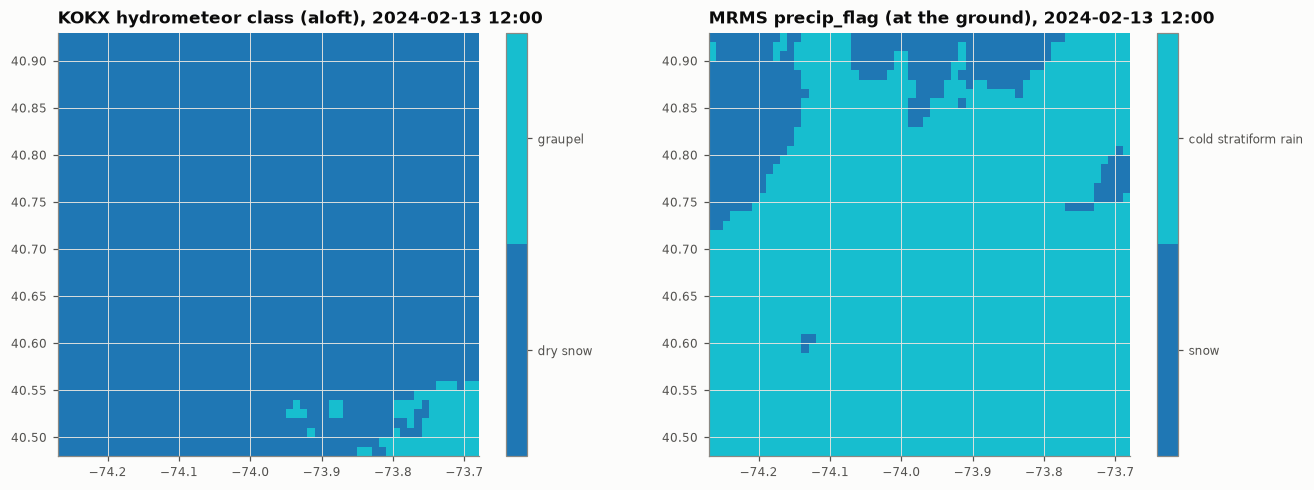

In [17]:
T = "2024-02-13 12:00"
kokx = xr.open_dataset(DATA / "data" / "weather" / "radar" / "openmesh_radar_kokx_snow_2024-02-13.nc")
mrms = xr.open_dataset(DATA / "data" / "weather" / "radar" / "openmesh_radar_snow_2024-02-13.nc")
KOKX = {0: "no echo", 30: "ice crystals", 40: "dry snow", 50: "wet snow", 60: "light/moderate rain",
        70: "heavy rain", 80: "big drops", 90: "graupel"}
MRMS = {0: "none", 1: "warm stratiform rain", 3: "snow", 6: "convective rain", 10: "cold stratiform rain"}

def type_map(ax, da, names, title):
    codes = [c for c in names if bool((da == c).any())]
    idx = sum(xr.where(da == c, i, 0) for i, c in enumerate(codes)).where(da.isin(codes))
    m = ax.pcolormesh(da.lon, da.lat, idx, cmap=plt.get_cmap("tab10", len(codes)), vmin=-0.5,
                      vmax=len(codes) - 0.5, shading="auto")
    cb = plt.colorbar(m, ax=ax, ticks=range(len(codes))); cb.ax.set_yticklabels([names[c] for c in codes])
    ax.set_title(title, loc="left"); ax.set_aspect(1 / np.cos(np.radians(40.7)))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
type_map(a1, kokx.hydrometeor_class.sel(time_10min=T), KOKX, f"KOKX hydrometeor class (aloft), {T}")
type_map(a2, mrms.precip_flag.sel(time_10min=T), MRMS, f"MRMS precip_flag (at the ground), {T}")
plt.show()